In [2]:
import csv
import io
import urllib.request
import numpy as np

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, balanced_accuracy_score, confusion_matrix,
    f1_score, precision_score, recall_score, roc_auc_score
)

S_URL = (
    "https://media.githubusercontent.com/media/onyekpeu/IO-VNBD/master/"
    "Synchronised%20V%20abd%20S%20datasets/Categorised%20IOVNB%20Dataset/"
    "M%20(Driver%20B)/S-M.csv"
)
V_URL = (
    "https://media.githubusercontent.com/media/onyekpeu/IO-VNBD/master/"
    "Synchronised%20V%20abd%20S%20datasets/Categorised%20IOVNB%20Dataset/"
    "M%20(Driver%20B)/V-M.csv"
)

S_FILE_SIZE = 19_798_721
V_FILE_SIZE = 22_507_823

# Inclusive byte ranges previously checked against these files.
RANGE_SPECS = {
    "prefix":     ((0, 1_048_575),           (0, 1_048_575)),
    "25% range":  ((4_949_680, 5_998_255),   (5_626_955, 6_675_530)),
    "50% range":  ((9_899_360, 10_947_935),  (1_579_772, 3_152_635)),
    "75% range":  ((14_849_040, 15_897_615), (7_244_402, 8_817_265)),
}

TOTAL_BYTES_READ = 0

def fetch_range(url, start, end, file_size):
    global TOTAL_BYTES_READ

    if not (0 <= start <= end < file_size):
        raise ValueError(f"Invalid range {start}-{end} for {file_size}-byte file")

    request = urllib.request.Request(
        url,
        headers={
            "Range": f"bytes={start}-{end}",
            "Accept-Encoding": "identity",
            "User-Agent": "Mozilla/5.0",
        },
    )

    with urllib.request.urlopen(request, timeout=60) as response:
        # Stop before reading if the server ignores the Range request.
        if response.status != 206:
            raise RuntimeError(
                f"Expected HTTP 206 for byte range; got {response.status}. "
                "Stopped without reading the response body."
            )

        content_range = response.headers.get("Content-Range", "")
        if not content_range.startswith(f"bytes {start}-{end}/"):
            raise RuntimeError(f"Unexpected Content-Range: {content_range!r}")

        data = response.read()

    expected = end - start + 1
    if len(data) != expected:
        raise RuntimeError(f"Expected {expected} bytes, received {len(data)}")

    TOTAL_BYTES_READ += len(data)
    return data

def complete_text(data):
    text = data.decode("utf-8-sig", errors="replace")
    # Discard a possibly partial final CSV record.
    if not data.endswith(b"\n"):
        last_newline = text.rfind("\n")
        if last_newline < 0:
            return ""
        text = text[:last_newline + 1]
    return text

def clean_rows(rows):
    result = []
    for row in rows:
        cleaned = {}
        for key, value in row.items():
            if key is None:
                continue
            key = key.strip()
            if isinstance(value, str):
                value = value.strip()
            cleaned[key] = value
        if any(value not in (None, "") for value in cleaned.values()):
            result.append(cleaned)
    return result

def parse_csv_range(data, start, fieldnames=None):
    text = complete_text(data)
    if not text:
        return [], fieldnames

    if start == 0:
        reader = csv.DictReader(io.StringIO(text))
        if not reader.fieldnames:
            raise RuntimeError("CSV header not found in the prefix range")
        fieldnames = [name.strip() for name in reader.fieldnames]
        reader.fieldnames = fieldnames
        return clean_rows(reader), fieldnames

    if not fieldnames:
        raise ValueError("A nonzero byte range needs the prefix header")

    # A nonzero range may start in the middle of a CSV row; discard that line.
    lines = text.splitlines()
    if lines:
        lines = lines[1:]

    reader = csv.DictReader(
        io.StringIO("\n".join(lines)),
        fieldnames=fieldnames
    )
    return clean_rows(reader), fieldnames

In [3]:
BLOCKS = {}
S_HEADERS = None
V_HEADERS = None

for block_name, (s_range, v_range) in RANGE_SPECS.items():
    s_bytes = fetch_range(S_URL, *s_range, S_FILE_SIZE)
    s_rows, S_HEADERS = parse_csv_range(s_bytes, s_range[0], S_HEADERS)

    v_bytes = fetch_range(V_URL, *v_range, V_FILE_SIZE)
    v_rows, V_HEADERS = parse_csv_range(v_bytes, v_range[0], V_HEADERS)

    BLOCKS[block_name] = {"S": s_rows, "V": v_rows}
    print(
        f"{block_name}: S rows={len(s_rows):,}, V rows={len(v_rows):,}"
    )

print(f"Total transferred: {TOTAL_BYTES_READ:,} bytes (ranges only)")

def one_channel(prefix):
    matches = [
        name for name in S_HEADERS
        if name.upper().startswith(prefix.upper())
    ]
    if len(matches) != 1:
        raise ValueError(f"Expected one column starting {prefix!r}; found {matches}")
    return matches[0]

PHONE_CHANNELS = [
    one_channel("ACCELEROMETER X "),
    one_channel("ACCELEROMETER Y "),
    one_channel("ACCELEROMETER Z "),
    one_channel("GYROSCOPE YAW "),
    one_channel("GYROSCOPE PITCH "),
    one_channel("GYROSCOPE ROLL "),
]

S_TIME = "TIME SINCE START (ms)"
V_TIME = "Time Since Start of Day (seconds)"
V_ECU_SPEED = "Indicated Vehicle Speed (km/hr)"

for column in (S_TIME, *PHONE_CHANNELS):
    if column not in S_HEADERS:
        raise KeyError(f"Missing S-M column: {column}")

for column in (V_TIME, V_ECU_SPEED):
    if column not in V_HEADERS:
        raise KeyError(f"Missing V-M column: {column}")

print("Phone inputs:")
for column in PHONE_CHANNELS:
    print(" ", column)
print("Offline label:", V_ECU_SPEED)

prefix: S rows=5,642, V rows=4,884
25% range: S rows=5,624, V rows=4,832
50% range: S rows=5,572, V rows=7,296
75% range: S rows=5,592, V rows=7,354
Total transferred: 9,437,184 bytes (ranges only)
Phone inputs:
  ACCELEROMETER X (m/s�)
  ACCELEROMETER Y (m/s�)
  ACCELEROMETER Z (m/s�)
  GYROSCOPE Yaw (rad/s)
  GYROSCOPE Pitch (rad/s)
  GYROSCOPE Roll (rad/s)
Offline label: Indicated Vehicle Speed (km/hr)


In [4]:
# Rebuild the prototype datasets without calling the old make_block().
import numpy as np

if "BLOCKS" in globals():
    NOWCAST_BLOCKS = BLOCKS
elif "segments_to_check" in globals():
    NOWCAST_BLOCKS = {
        name: {"S": s_rows, "V": v_rows}
        for name, s_rows, v_rows in segments_to_check
    }
else:
    raise NameError(
        "Raw data is not loaded. Run the range-loading cell first."
    )

PHONE_TO_VM_OFFSET_SECONDS = 29_604.173
WINDOW = 20
MAX_LABEL_AGE_SECONDS = 0.12
MAX_CONTIGUOUS_GAP_SECONDS = 0.15
TRAIN_STRIDE = 2
EVAL_STRIDE = 20

S_TIME_NOWCAST = "TIME SINCE START (ms)"
V_TIME_NOWCAST = "Time Since Start of Day (seconds)"
V_SPEED_NOWCAST = "Indicated Vehicle Speed (km/hr)"

sample_s_rows = next(
    data["S"] for data in NOWCAST_BLOCKS.values() if data["S"]
)
s_headers = list(sample_s_rows[0].keys())

def find_channel(prefix):
    matches = [
        col for col in s_headers
        if col.upper().startswith(prefix.upper())
    ]
    if len(matches) != 1:
        raise ValueError(f"Expected one column starting {prefix!r}; found {matches}")
    return matches[0]

PHONE_CHANNELS = [
    find_channel("ACCELEROMETER X "),
    find_channel("ACCELEROMETER Y "),
    find_channel("ACCELEROMETER Z "),
    find_channel("GYROSCOPE YAW "),
    find_channel("GYROSCOPE PITCH "),
    find_channel("GYROSCOPE ROLL "),
]

def nowcast_number(row, column):
    try:
        return float(row[column])
    except (KeyError, TypeError, ValueError):
        return np.nan

def nowcast_window_features(window):
    return np.concatenate([
        window.mean(axis=0),
        window.std(axis=0),
        np.ptp(window, axis=0),
        window[-1] - window[0],
    ])

# Keep the name expected by the model/evaluation cell.
window_features = nowcast_window_features

def build_nowcast_block(block_name, stride, keep_windows=False, verbose=True):
    s_rows = NOWCAST_BLOCKS[block_name]["S"]
    v_rows = NOWCAST_BLOCKS[block_name]["V"]

    phone_t = np.asarray([
        nowcast_number(row, S_TIME_NOWCAST) / 1000
        + PHONE_TO_VM_OFFSET_SECONDS
        for row in s_rows
    ])
    phone_x = np.asarray([
        [nowcast_number(row, col) for col in PHONE_CHANNELS]
        for row in s_rows
    ])

    phone_ok = np.isfinite(phone_t) & np.all(np.isfinite(phone_x), axis=1)
    phone_t, phone_x = phone_t[phone_ok], phone_x[phone_ok]
    order = np.argsort(phone_t)
    phone_t, phone_x = phone_t[order], phone_x[order]
    phone_t, unique = np.unique(phone_t, return_index=True)
    phone_x = phone_x[unique]

    vm_t = np.asarray([
        nowcast_number(row, V_TIME_NOWCAST) for row in v_rows
    ])
    ecu_speed = np.asarray([
        nowcast_number(row, V_SPEED_NOWCAST) for row in v_rows
    ])
    vm_ok = np.isfinite(vm_t) & np.isfinite(ecu_speed)
    vm_t, ecu_speed = vm_t[vm_ok], ecu_speed[vm_ok]

    if len(vm_t) == 0:
        raise ValueError(f"{block_name}: no valid V-M speed rows")

    order = np.argsort(vm_t)
    vm_t, ecu_speed = vm_t[order], ecu_speed[order]
    vm_t, unique = np.unique(vm_t, return_index=True)
    ecu_speed = ecu_speed[unique]

    # Use the latest ECU sample at or before each phone timestamp.
    idx = np.searchsorted(vm_t, phone_t, side="right") - 1
    has_prior = idx >= 0
    idx_safe = np.clip(idx, 0, len(vm_t) - 1)
    label_age = phone_t - vm_t[idx_safe]

    matched = (
        has_prior
        & (label_age >= 0)
        & (label_age <= MAX_LABEL_AGE_SECONDS)
    )

    t = phone_t[matched]
    x = phone_x[matched]
    speed = ecu_speed[idx_safe[matched]]
    age = label_age[matched]

    if verbose and len(age):
        print(
            f"{block_name}: matched {len(t):,} rows; "
            f"label age p95/max="
            f"{np.percentile(age, 95):.3f}/{np.max(age):.3f}s"
        )

    features, labels, times, speeds, raw_windows = [], [], [], [], []
    cuts = np.flatnonzero(np.diff(t) > MAX_CONTIGUOUS_GAP_SECONDS) + 1
    runs = np.split(np.arange(len(t)), cuts)

    for run in runs:
        if len(run) < WINDOW:
            continue

        for end in range(WINDOW - 1, len(run), stride):
            row_idx = run[end]
            current_speed = speed[row_idx]

            if current_speed <= 1.0:
                label = 1  # stationary
            elif current_speed >= 5.0:
                label = 0  # moving
            else:
                continue  # ignore the 1–5 km/h creep band

            window = x[run[end - WINDOW + 1:end + 1]]
            features.append(nowcast_window_features(window))
            labels.append(label)
            times.append(t[row_idx])
            speeds.append(current_speed)

            if keep_windows:
                raw_windows.append(window.copy())

    result = {
        "X": np.asarray(features, dtype=np.float32).reshape(
            -1, 4 * len(PHONE_CHANNELS)
        ),
        "y": np.asarray(labels, dtype=np.int64),
        "time": np.asarray(times),
        "speed_kmh": np.asarray(speeds),
    }

    if keep_windows:
        result["windows"] = np.asarray(
            raw_windows, dtype=np.float32
        ).reshape(-1, WINDOW, len(PHONE_CHANNELS))

    if verbose:
        print(
            f"  windows={len(result['y']):,}; "
            f"moving={np.sum(result['y'] == 0):,}; "
            f"stationary={np.sum(result['y'] == 1):,}"
        )

    return result

TRAIN_BLOCKS = ["prefix", "50% range"]
VALIDATION_BLOCK = "25% range"
TEST_BLOCK = "75% range"

train_parts = [
    build_nowcast_block(name, stride=TRAIN_STRIDE, verbose=True)
    for name in TRAIN_BLOCKS
]
X_train = np.concatenate([part["X"] for part in train_parts])
y_train = np.concatenate([part["y"] for part in train_parts])

eval_data = {
    name: build_nowcast_block(
        name,
        stride=EVAL_STRIDE,
        keep_windows=(name == TEST_BLOCK),
        verbose=True,
    )
    for name in NOWCAST_BLOCKS
}

print("Training examples:", len(y_train))
print("Training counts [moving, stationary]:",
      np.bincount(y_train, minlength=2))

prefix: matched 4,884 rows; label age p95/max=0.100/0.100s
  windows=2,408; moving=2,400; stationary=8
50% range: matched 5,572 rows; label age p95/max=0.083/0.088s
  windows=2,651; moving=2,488; stationary=163
prefix: matched 4,884 rows; label age p95/max=0.100/0.100s
  windows=243; moving=242; stationary=1
25% range: matched 4,437 rows; label age p95/max=0.100/0.101s
  windows=215; moving=206; stationary=9
50% range: matched 5,572 rows; label age p95/max=0.083/0.088s
  windows=266; moving=250; stationary=16
75% range: matched 5,592 rows; label age p95/max=0.049/0.056s
  windows=268; moving=237; stationary=31
Training examples: 5059
Training counts [moving, stationary]: [4888  171]


In [5]:
model = make_pipeline(
    StandardScaler(),  # fitted on training data only
    LogisticRegression(
        class_weight="balanced",
        max_iter=1500,
        solver="liblinear",
        random_state=7,
    ),
)
model.fit(X_train, y_train)

positive_index = list(
    model.named_steps["logisticregression"].classes_
).index(1)

val = eval_data[VALIDATION_BLOCK]
if len(val["y"]) == 0:
    raise ValueError("Validation block produced no evaluation windows.")

val_prob = model.predict_proba(val["X"])[:, positive_index]

if len(np.unique(val["y"])) == 2:
    thresholds = np.linspace(0.05, 0.95, 91)
    scores = [
        balanced_accuracy_score(val["y"], val_prob >= threshold)
        for threshold in thresholds
    ]
    threshold = float(thresholds[int(np.argmax(scores))])
else:
    threshold = 0.50
    print("Validation has one class; using threshold 0.50.")

print(f"Validation-selected stationary threshold: {threshold:.2f}")

def report_block(name, data):
    y = data["y"]
    if len(y) == 0:
        print(f"{name}: no evaluation windows")
        return

    probability = model.predict_proba(data["X"])[:, positive_index]
    prediction = (probability >= threshold).astype(int)
    cm = confusion_matrix(y, prediction, labels=[0, 1])

    has_two_classes = len(np.unique(y)) == 2
    roc_auc = roc_auc_score(y, probability) if has_two_classes else np.nan
    pr_auc = average_precision_score(y, probability) if has_two_classes else np.nan

    print(
        f"{name}: n={len(y)}, ROC-AUC={roc_auc:.3f}, "
        f"PR-AUC/AP={pr_auc:.3f}, "
        f"balanced accuracy={balanced_accuracy_score(y, prediction):.3f}, "
        f"stationary precision={precision_score(y, prediction, zero_division=0):.3f}, "
        f"recall={recall_score(y, prediction, zero_division=0):.3f}, "
        f"F1={f1_score(y, prediction, zero_division=0):.3f}"
    )
    print("  confusion [[TN, FP], [FN, TP]]:", cm.tolist())

for name in ["prefix", "50% range", VALIDATION_BLOCK, TEST_BLOCK]:
    role = "train / in-sample" if name in TRAIN_BLOCKS else "held-out"
    print(f"\n{name} ({role})")
    report_block(name, eval_data[name])

def predict_current_window(window):
    """Predict current state from the latest 20 phone samples (20 x 6)."""
    window = np.asarray(window, dtype=np.float32)
    expected_shape = (WINDOW, len(PHONE_CHANNELS))
    if window.shape != expected_shape:
        raise ValueError(f"Expected shape {expected_shape}, got {window.shape}")

    features = window_features(window).reshape(1, -1)
    p_stationary = float(
        model.predict_proba(features)[0, positive_index]
    )
    state = "stationary" if p_stationary >= threshold else "moving"
    return state, p_stationary

test = eval_data[TEST_BLOCK]
if len(test.get("windows", [])):
    state, p_stationary = predict_current_window(test["windows"][-1])
    actual = "stationary" if test["y"][-1] == 1 else "moving"
    print(
        f"\nHeld-out example at t={test['time'][-1]:.1f}s: "
        f"prediction={state}, P(stationary)={p_stationary:.2f}; "
        f"offline ECU label={actual} "
        f"({test['speed_kmh'][-1]:.1f} km/h)"
    )

Validation-selected stationary threshold: 0.05

prefix (train / in-sample)
prefix: n=243, ROC-AUC=0.959, PR-AUC/AP=0.091, balanced accuracy=0.820, stationary precision=0.011, recall=1.000, F1=0.022
  confusion [[TN, FP], [FN, TP]]: [[155, 87], [0, 1]]

50% range (train / in-sample)
50% range: n=266, ROC-AUC=0.824, PR-AUC/AP=0.282, balanced accuracy=0.540, stationary precision=0.065, recall=1.000, F1=0.122
  confusion [[TN, FP], [FN, TP]]: [[20, 230], [0, 16]]

25% range (held-out)
25% range: n=215, ROC-AUC=0.785, PR-AUC/AP=0.101, balanced accuracy=0.779, stationary precision=0.090, recall=1.000, F1=0.165
  confusion [[TN, FP], [FN, TP]]: [[115, 91], [0, 9]]

75% range (held-out)
75% range: n=268, ROC-AUC=0.456, PR-AUC/AP=0.119, balanced accuracy=0.474, stationary precision=0.110, recall=0.935, F1=0.197
  confusion [[TN, FP], [FN, TP]]: [[3, 234], [2, 29]]

Held-out example at t=33698.0s: prediction=stationary, P(stationary)=0.76; offline ECU label=stationary (0.0 km/h)


In [6]:
from sklearn.metrics import (
    balanced_accuracy_score, precision_score, recall_score, f1_score
)

val = eval_data["25% range"]
p_stationary = model.predict_proba(val["X"])[:, positive_index]

for threshold in [0.05, 0.10, 0.20, 0.35, 0.50, 0.65, 0.80, 0.90]:
    pred = (p_stationary >= threshold).astype(int)
    print(
        f"threshold={threshold:.2f}  "
        f"predicted stationary={pred.sum()}/{len(pred)}  "
        f"balanced accuracy={balanced_accuracy_score(val['y'], pred):.3f}  "
        f"precision={precision_score(val['y'], pred, zero_division=0):.3f}  "
        f"recall={recall_score(val['y'], pred, zero_division=0):.3f}  "
        f"F1={f1_score(val['y'], pred, zero_division=0):.3f}"
    )

threshold=0.05  predicted stationary=100/215  balanced accuracy=0.779  precision=0.090  recall=1.000  F1=0.165
threshold=0.10  predicted stationary=72/215  balanced accuracy=0.731  precision=0.097  recall=0.778  F1=0.173
threshold=0.20  predicted stationary=46/215  balanced accuracy=0.736  precision=0.130  recall=0.667  F1=0.218
threshold=0.35  predicted stationary=24/215  balanced accuracy=0.558  precision=0.083  recall=0.222  F1=0.121
threshold=0.50  predicted stationary=12/215  balanced accuracy=0.471  precision=0.000  recall=0.000  F1=0.000
threshold=0.65  predicted stationary=6/215  balanced accuracy=0.485  precision=0.000  recall=0.000  F1=0.000
threshold=0.80  predicted stationary=3/215  balanced accuracy=0.493  precision=0.000  recall=0.000  F1=0.000
threshold=0.90  predicted stationary=1/215  balanced accuracy=0.498  precision=0.000  recall=0.000  F1=0.000


In [7]:
import numpy as np

if "BLOCKS" not in globals():
    raise NameError("Run the data range-loading cell first; BLOCKS is missing.")

S_TIME = "TIME SINCE START (ms)"
V_TIME = "Time Since Start of Day (seconds)"
V_ECU_SPEED = "Indicated Vehicle Speed (km/hr)"
PHONE_TO_VM_OFFSET_SECONDS = 29_604.173

def cal_num(row, column):
    try:
        return float(row[column])
    except (KeyError, TypeError, ValueError):
        return np.nan

def cal_channel(headers, prefix):
    matches = [c for c in headers if c.upper().startswith(prefix.upper())]
    if len(matches) != 1:
        raise ValueError(f"Expected one column starting {prefix!r}; found {matches}")
    return matches[0]

# Use the six selected phone channels only.
sample_rows = next(block["S"] for block in BLOCKS.values() if block["S"])
headers = list(sample_rows[0].keys())

ACC_COLS = [
    cal_channel(headers, "ACCELEROMETER X "),
    cal_channel(headers, "ACCELEROMETER Y "),
    cal_channel(headers, "ACCELEROMETER Z "),
]
GYRO_COLS = [
    cal_channel(headers, "GYROSCOPE YAW "),
    cal_channel(headers, "GYROSCOPE PITCH "),
    cal_channel(headers, "GYROSCOPE ROLL "),
]

def find_stationary_calibration(block_name, min_samples=20):
    s_rows = BLOCKS[block_name]["S"]
    v_rows = BLOCKS[block_name]["V"]

    phone_t = np.asarray([
        cal_num(r, S_TIME) / 1000 + PHONE_TO_VM_OFFSET_SECONDS
        for r in s_rows
    ])
    acc = np.asarray([[cal_num(r, c) for c in ACC_COLS] for r in s_rows])
    gyro = np.asarray([[cal_num(r, c) for c in GYRO_COLS] for r in s_rows])

    good_phone = (
        np.isfinite(phone_t)
        & np.all(np.isfinite(acc), axis=1)
        & np.all(np.isfinite(gyro), axis=1)
    )
    phone_t, acc, gyro = phone_t[good_phone], acc[good_phone], gyro[good_phone]

    order = np.argsort(phone_t)
    phone_t, acc, gyro = phone_t[order], acc[order], gyro[order]
    phone_t, unique = np.unique(phone_t, return_index=True)
    acc, gyro = acc[unique], gyro[unique]

    vm_t = np.asarray([cal_num(r, V_TIME) for r in v_rows])
    vm_speed = np.asarray([cal_num(r, V_ECU_SPEED) for r in v_rows])
    good_vm = np.isfinite(vm_t) & np.isfinite(vm_speed)
    vm_t, vm_speed = vm_t[good_vm], vm_speed[good_vm]

    order = np.argsort(vm_t)
    vm_t, vm_speed = vm_t[order], vm_speed[order]
    vm_t, unique = np.unique(vm_t, return_index=True)
    vm_speed = vm_speed[unique]

    if len(vm_t) == 0:
        print(f"{block_name}: no usable ECU-speed labels")
        return

    # Causal match: most recent V-M sample at or before each phone timestamp.
    idx = np.searchsorted(vm_t, phone_t, side="right") - 1
    has_prior = idx >= 0
    idx_safe = np.clip(idx, 0, len(vm_t) - 1)
    age = phone_t - vm_t[idx_safe]
    valid = has_prior & (age >= 0) & (age <= 0.12)

    stopped = valid & (vm_speed[idx_safe] <= 1.0)
    stop_indices = np.flatnonzero(stopped)

    if len(stop_indices) == 0:
        print(f"{block_name}: no ECU-labelled stationary samples")
        return

    # Split stationary samples at gaps; retain runs of at least 2 seconds.
    split_points = np.flatnonzero(
        np.diff(phone_t[stop_indices]) > 0.15
    ) + 1
    runs = np.split(stop_indices, split_points)
    runs = [r for r in runs if len(r) >= min_samples]

    if not runs:
        print(f"{block_name}: no stationary run of at least {min_samples} samples")
        return

    runs.sort(key=len, reverse=True)
    print(f"{block_name}: {len(runs)} stationary calibration run(s) ≥2 s")

    for run in runs[:3]:
        mean_acc = acc[run].mean(axis=0)
        mean_gyro = gyro[run].mean(axis=0)
        duration = phone_t[run[-1]] - phone_t[run[0]]

        print(
            f"  n={len(run)}, duration={duration:.1f}s, "
            f"gravity-vector magnitude≈{np.linalg.norm(mean_acc):.2f} m/s²"
        )
        print("  mean accelerometer [phone axes]:", np.round(mean_acc, 4))
        print("  mean gyro bias [Yaw, Pitch, Roll] rad/s:", np.round(mean_gyro, 5))

for block_name in BLOCKS:
    find_stationary_calibration(block_name)

prefix: no stationary run of at least 20 samples
25% range: 4 stationary calibration run(s) ≥2 s
  n=95, duration=9.4s, gravity-vector magnitude≈9.81 m/s²
  mean accelerometer [phone axes]: [ 0.2197 -0.466   9.7959]
  mean gyro bias [Yaw, Pitch, Roll] rad/s: [ 6.89e-03 -6.00e-05  3.29e-03]
  n=61, duration=6.0s, gravity-vector magnitude≈9.81 m/s²
  mean accelerometer [phone axes]: [ 0.4899 -0.5298  9.7884]
  mean gyro bias [Yaw, Pitch, Roll] rad/s: [ 0.00658 -0.00833  0.00139]
  n=24, duration=2.3s, gravity-vector magnitude≈9.83 m/s²
  mean accelerometer [phone axes]: [ 0.0194 -0.3292  9.8207]
  mean gyro bias [Yaw, Pitch, Roll] rad/s: [0.0048  0.00048 0.00097]
50% range: 8 stationary calibration run(s) ≥2 s
  n=56, duration=5.5s, gravity-vector magnitude≈10.06 m/s²
  mean accelerometer [phone axes]: [-0.9658 -0.6006  9.9936]
  mean gyro bias [Yaw, Pitch, Roll] rad/s: [ 8.60e-04  4.77e-03 -6.00e-05]
  n=56, duration=5.5s, gravity-vector magnitude≈9.91 m/s²
  mean accelerometer [phone a

In [8]:
import numpy as np

OFFSET_S = 29_604.173
S_TIME_COL = "TIME SINCE START (ms)"
V_TIME_COL = "Time Since Start of Day (seconds)"
ECU_SPEED_COL = "Indicated Vehicle Speed (km/hr)"

# Find the exact six channels from the S-M headers.
example_s = next(b["S"] for b in BLOCKS.values() if b["S"])
headers = list(example_s[0].keys())

def _find_col(prefix):
    matches = [c for c in headers if c.upper().startswith(prefix.upper())]
    if len(matches) != 1:
        raise ValueError(f"Expected one column starting {prefix!r}; found {matches}")
    return matches[0]

_ACC = [
    _find_col("ACCELEROMETER X "),
    _find_col("ACCELEROMETER Y "),
    _find_col("ACCELEROMETER Z "),
]
_GYRO = [
    _find_col("GYROSCOPE YAW "),
    _find_col("GYROSCOPE PITCH "),
    _find_col("GYROSCOPE ROLL "),
]

def _num(row, col):
    try:
        return float(row[col])
    except (KeyError, TypeError, ValueError):
        return np.nan

STATIC_RUNS = []

for block_name, block in BLOCKS.items():
    s_rows, v_rows = block["S"], block["V"]

    pt = np.asarray([
        _num(r, S_TIME_COL) / 1000 + OFFSET_S for r in s_rows
    ])
    acc = np.asarray([[_num(r, c) for c in _ACC] for r in s_rows])
    gyro = np.asarray([[_num(r, c) for c in _GYRO] for r in s_rows])

    good = np.isfinite(pt) & np.all(np.isfinite(acc), axis=1) & np.all(np.isfinite(gyro), axis=1)
    pt, acc, gyro = pt[good], acc[good], gyro[good]
    order = np.argsort(pt)
    pt, acc, gyro = pt[order], acc[order], gyro[order]
    pt, unique = np.unique(pt, return_index=True)
    acc, gyro = acc[unique], gyro[unique]

    vt = np.asarray([_num(r, V_TIME_COL) for r in v_rows])
    vs = np.asarray([_num(r, ECU_SPEED_COL) for r in v_rows])
    good_v = np.isfinite(vt) & np.isfinite(vs)
    vt, vs = vt[good_v], vs[good_v]
    if len(vt) == 0:
        continue

    order = np.argsort(vt)
    vt, vs = vt[order], vs[order]
    vt, unique = np.unique(vt, return_index=True)
    vs = vs[unique]

    # Causal match to the latest ECU sample at or before each phone sample.
    idx = np.searchsorted(vt, pt, side="right") - 1
    has_prior = idx >= 0
    safe_idx = np.clip(idx, 0, len(vt) - 1)
    age = pt - vt[safe_idx]
    stopped = has_prior & (age >= 0) & (age <= 0.12) & (vs[safe_idx] <= 1.0)

    stop_idx = np.flatnonzero(stopped)
    if len(stop_idx) == 0:
        print(f"{block_name}: no stationary candidates")
        continue

    cuts = np.flatnonzero(np.diff(pt[stop_idx]) > 0.15) + 1
    runs = [r for r in np.split(stop_idx, cuts) if len(r) >= 20]

    for run in runs:
        a, g = acc[run], gyro[run]
        a_mean, g_mean = a.mean(axis=0), g.mean(axis=0)
        acc_fluctuation = np.sqrt(np.mean(np.sum((a - a_mean) ** 2, axis=1)))
        gyro_fluctuation = np.sqrt(np.mean(np.sum((g - g_mean) ** 2, axis=1)))
        gyro_rms = np.sqrt(np.mean(np.sum(g ** 2, axis=1)))

        STATIC_RUNS.append({
            "block": block_name,
            "start_s": float(pt[run[0]]),
            "end_s": float(pt[run[-1]]),
            "duration_s": float(pt[run[-1]] - pt[run[0]]),
            "n": len(run),
            "gravity_norm": float(np.linalg.norm(a_mean)),
            "acc_fluctuation": float(acc_fluctuation),
            "gyro_rms": float(gyro_rms),
            "gyro_fluctuation": float(gyro_fluctuation),
            "acc_mean": a_mean,
            "gyro_mean": g_mean,
        })

STATIC_RUNS.sort(key=lambda r: (r["gyro_fluctuation"], r["acc_fluctuation"]))

for r in STATIC_RUNS:
    print(
        f"{r['block']}: {r['start_s']:.1f}–{r['end_s']:.1f}s, "
        f"duration={r['duration_s']:.1f}s, n={r['n']}, "
        f"|mean accel|={r['gravity_norm']:.2f}, "
        f"acc fluctuation={r['acc_fluctuation']:.3f} m/s², "
        f"gyro RMS={r['gyro_rms']:.4f} rad/s, "
        f"gyro fluctuation={r['gyro_fluctuation']:.4f} rad/s"
    )
    print("  mean accel:", np.round(r["acc_mean"], 4))
    print("  mean gyro: ", np.round(r["gyro_mean"], 5))

75% range: 33232.7–33236.7s, duration=4.0s, n=41, |mean accel|=9.86, acc fluctuation=0.171 m/s², gyro RMS=0.0254 rad/s, gyro fluctuation=0.0209 rad/s
  mean accel: [ 0.2907 -0.4425  9.8456]
  mean gyro:  [-0.0033   0.01339 -0.00426]
25% range: 32547.0–32549.3s, duration=2.3s, n=24, |mean accel|=9.83, acc fluctuation=0.533 m/s², gyro RMS=0.0219 rad/s, gyro fluctuation=0.0213 rad/s
  mean accel: [ 0.0194 -0.3292  9.8207]
  mean gyro:  [0.0048  0.00048 0.00097]
50% range: 31039.8–31042.2s, duration=2.4s, n=25, |mean accel|=9.70, acc fluctuation=0.524 m/s², gyro RMS=0.0327 rad/s, gyro fluctuation=0.0298 rad/s
  mean accel: [-0.646   0.1241  9.6728]
  mean gyro:  [-0.00784  0.01038  0.00376]
25% range: 32502.7–32508.7s, duration=6.0s, n=61, |mean accel|=9.81, acc fluctuation=1.518 m/s², gyro RMS=0.0359 rad/s, gyro fluctuation=0.0343 rad/s
  mean accel: [ 0.4899 -0.5298  9.7884]
  mean gyro:  [ 0.00658 -0.00833  0.00139]
50% range: 30610.2–30613.2s, duration=3.0s, n=31, |mean accel|=9.95, ac

Calibration: 75% range, 33232.7–33236.7s
Propagation samples=601, dt median/p95/max=0.100/0.101/0.104s
Oracle-ZUPT samples: 42
Final no-ZUPT position / speed: [-449.69  164.29] m / 35.82 m/s
Final oracle-ZUPT position / speed: [-202.36   41.37] m / 30.03 m/s


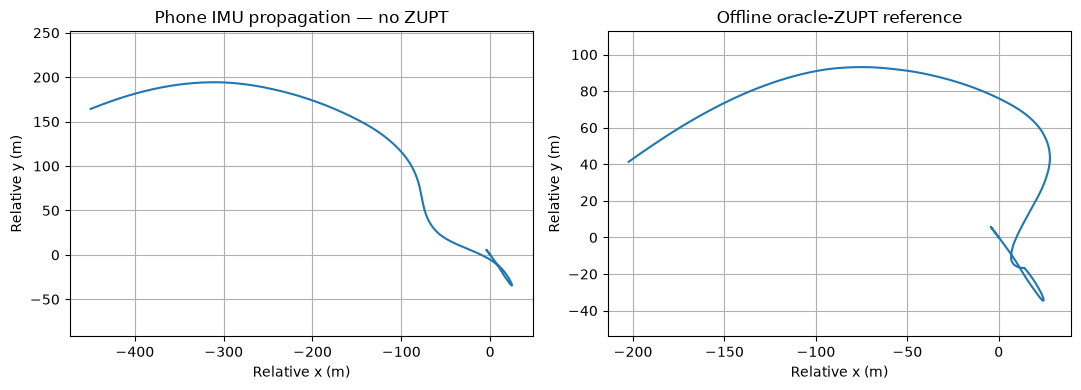

In [9]:
import numpy as np
import matplotlib.pyplot as plt

if "BLOCKS" not in globals() or "STATIC_RUNS" not in globals():
    raise NameError("Run the range-loading and static-run audit cells first.")

# STATIC_RUNS is sorted by low gyro/acceleration fluctuation.
cal = STATIC_RUNS[0]
block_name = cal["block"]
print(
    f"Calibration: {block_name}, "
    f"{cal['start_s']:.1f}–{cal['end_s']:.1f}s"
)

DR_S_TIME = "TIME SINCE START (ms)"
DR_V_TIME = "Time Since Start of Day (seconds)"
DR_V_SPEED = "Indicated Vehicle Speed (km/hr)"
DR_OFFSET_S = 29_604.173
DR_DURATION_S = 60.0

s_rows = BLOCKS[block_name]["S"]
v_rows = BLOCKS[block_name]["V"]
headers = list(s_rows[0].keys())

def dr_col(prefix):
    matches = [c for c in headers if c.upper().startswith(prefix.upper())]
    if len(matches) != 1:
        raise ValueError(f"Expected one column starting {prefix!r}; found {matches}")
    return matches[0]

DR_ACC_COLS = [
    dr_col("ACCELEROMETER X "),
    dr_col("ACCELEROMETER Y "),
    dr_col("ACCELEROMETER Z "),
]
DR_GYRO_YAW_COL = dr_col("GYROSCOPE YAW ")

def dr_num(row, col):
    try:
        return float(row[col])
    except (KeyError, TypeError, ValueError):
        return np.nan

# Phone IMU, corrected onto the V-M time base.
phone_t = np.asarray([
    dr_num(r, DR_S_TIME) / 1000 + DR_OFFSET_S for r in s_rows
])
acc = np.asarray([
    [dr_num(r, c) for c in DR_ACC_COLS] for r in s_rows
])
gyro_yaw = np.asarray([
    dr_num(r, DR_GYRO_YAW_COL) for r in s_rows
])

good = (
    np.isfinite(phone_t)
    & np.all(np.isfinite(acc), axis=1)
    & np.isfinite(gyro_yaw)
)
phone_t, acc, gyro_yaw = phone_t[good], acc[good], gyro_yaw[good]
order = np.argsort(phone_t)
phone_t, acc, gyro_yaw = phone_t[order], acc[order], gyro_yaw[order]
phone_t, unique = np.unique(phone_t, return_index=True)
acc, gyro_yaw = acc[unique], gyro_yaw[unique]

# Keep 60 seconds after the selected stationary calibration interval.
keep = (
    (phone_t >= cal["end_s"])
    & (phone_t <= cal["end_s"] + DR_DURATION_S)
)
t = phone_t[keep]
acc = acc[keep]
gyro_yaw = gyro_yaw[keep]

if len(t) < 3:
    raise ValueError("Not enough phone samples after calibration.")

dt = np.diff(t)
print(
    f"Propagation samples={len(t)}, dt median/p95/max="
    f"{np.median(dt):.3f}/{np.percentile(dt, 95):.3f}/{np.max(dt):.3f}s"
)

# Calibrate gravity/accelerometer offset and gyro bias from the selected stop.
gravity_phone = np.asarray(cal["acc_mean"])
gyro_bias_yaw = float(cal["gyro_mean"][0])
up = gravity_phone / np.linalg.norm(gravity_phone)

# Arbitrary horizontal phone-frame basis; this is not vehicle-forward or north.
reference_axis = np.array([1.0, 0.0, 0.0])
if abs(np.dot(reference_axis, up)) > 0.9:
    reference_axis = np.array([0.0, 1.0, 0.0])
e1 = reference_axis - np.dot(reference_axis, up) * up
e1 /= np.linalg.norm(e1)
e2 = np.cross(up, e1)
e2 /= np.linalg.norm(e2)

# Remove the calibrated gravity vector and project into the phone's horizontal plane.
linear_acc = acc - gravity_phone
acc_body = np.column_stack((linear_acc @ e1, linear_acc @ e2))

# Provisional assumption: this channel measures rotation about the local vertical.
omega = gyro_yaw - gyro_bias_yaw
yaw = np.zeros(len(t))
yaw[1:] = np.cumsum(0.5 * (omega[:-1] + omega[1:]) * dt)

# Rotate horizontal phone-frame acceleration into the arbitrary initial path frame.
acc_path = np.empty_like(acc_body)
for i, angle in enumerate(yaw):
    c, s = np.cos(angle), np.sin(angle)
    rotation = np.array([[c, -s], [s, c]])
    acc_path[i] = rotation @ acc_body[i]

# Offline ECU labels: used only for the oracle-ZUPT comparison.
vm_t = np.asarray([dr_num(r, DR_V_TIME) for r in v_rows])
vm_speed = np.asarray([dr_num(r, DR_V_SPEED) for r in v_rows])
vm_good = np.isfinite(vm_t) & np.isfinite(vm_speed)
vm_t, vm_speed = vm_t[vm_good], vm_speed[vm_good]
order = np.argsort(vm_t)
vm_t, vm_speed = vm_t[order], vm_speed[order]
vm_t, unique = np.unique(vm_t, return_index=True)
vm_speed = vm_speed[unique]

idx = np.searchsorted(vm_t, t, side="right") - 1
has_prior = idx >= 0
idx_safe = np.clip(idx, 0, len(vm_t) - 1)
label_age = t - vm_t[idx_safe]
oracle_stop = (
    has_prior
    & (label_age >= 0)
    & (label_age <= 0.12)
    & (vm_speed[idx_safe] <= 1.0)
)

# Only apply oracle resets for stops lasting at least 0.5 seconds.
stop_indices = np.flatnonzero(oracle_stop)
persistent_stop = np.zeros(len(t), dtype=bool)
cuts = np.flatnonzero(np.diff(t[stop_indices]) > 0.15) + 1
for run in np.split(stop_indices, cuts):
    if len(run) >= 5:
        persistent_stop[run] = True

def integrate_path(use_zupt):
    position = np.zeros((len(t), 2))
    velocity = np.zeros((len(t), 2))

    for k in range(1, len(t)):
        step = t[k] - t[k - 1]
        a_mid = 0.5 * (acc_path[k - 1] + acc_path[k])
        v_new = velocity[k - 1] + a_mid * step

        if use_zupt and persistent_stop[k]:
            v_new[:] = 0.0

        position[k] = position[k - 1] + 0.5 * (
            velocity[k - 1] + v_new
        ) * step
        velocity[k] = v_new

    return position, velocity

path_no_zupt, vel_no_zupt = integrate_path(use_zupt=False)
path_oracle, vel_oracle = integrate_path(use_zupt=True)

print("Oracle-ZUPT samples:", int(persistent_stop.sum()))
print("Final no-ZUPT position / speed:",
      np.round(path_no_zupt[-1], 2), "m /",
      round(np.linalg.norm(vel_no_zupt[-1]), 2), "m/s")
print("Final oracle-ZUPT position / speed:",
      np.round(path_oracle[-1], 2), "m /",
      round(np.linalg.norm(vel_oracle[-1]), 2), "m/s")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(path_no_zupt[:, 0], path_no_zupt[:, 1])
axes[0].set_title("Phone IMU propagation — no ZUPT")
axes[1].plot(path_oracle[:, 0], path_oracle[:, 1])
axes[1].set_title("Offline oracle-ZUPT reference")
for ax in axes:
    ax.set_xlabel("Relative x (m)")
    ax.set_ylabel("Relative y (m)")
    ax.axis("equal")
    ax.grid(True)
plt.tight_layout()
plt.show()

Final oracle-EKF position / speed: [ 49.98 -27.  ] m / 20.11 m/s
Estimated residual accel bias: [-0.5614 -0.0219] m/s²
Estimated residual gyro bias: -0.01902 rad/s


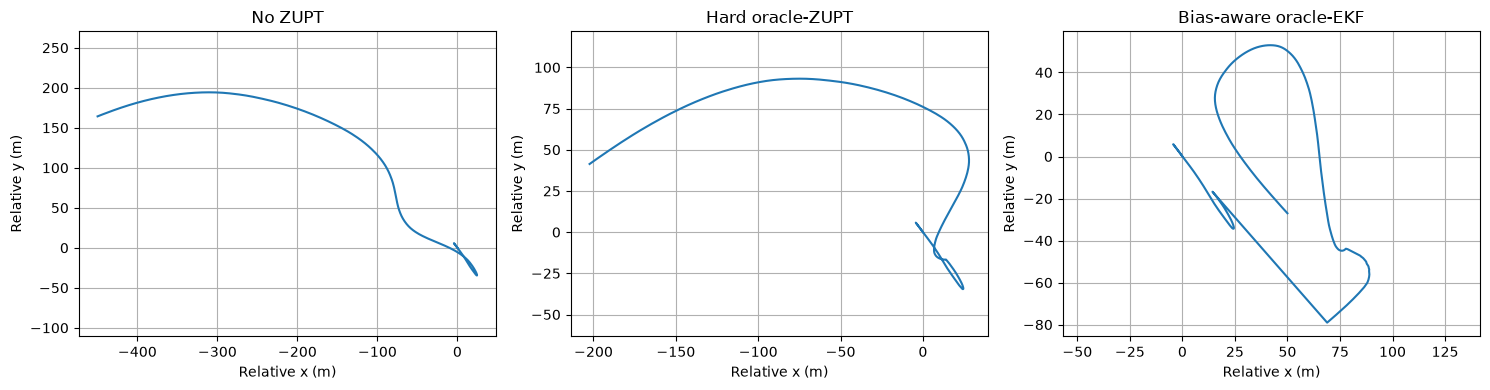

In [10]:
import numpy as np
import matplotlib.pyplot as plt

required = ("t", "acc_body", "omega", "persistent_stop")
missing = [name for name in required if name not in globals()]
if missing:
    raise NameError(f"Run the propagation cell first; missing: {missing}")

def run_oracle_zupt_ekf(
    t, acc_body, omega, zupt_mask,
    sigma_acc=0.20,       # m/s² process-noise scale; initial debug value
    sigma_gyro=0.02,      # rad/s process-noise scale
    sigma_acc_bias=0.005, # m/s² / sqrt(second)
    sigma_gyro_bias=0.001,# rad/s / sqrt(second)
    sigma_zupt=0.05       # m/s zero-velocity measurement noise
):
    n = len(t)

    # State: [px, py, vx, vy, yaw, bax, bay, bg]
    state = np.zeros(8)
    covariance = np.diag([
        0.01**2, 0.01**2,
        0.20**2, 0.20**2,
        np.deg2rad(5)**2,
        0.20**2, 0.20**2,
        0.02**2,
    ])

    history = np.zeros((n, 8))
    history[0] = state

    H = np.zeros((2, 8))
    H[0, 2] = 1.0
    H[1, 3] = 1.0
    R_zupt = np.eye(2) * sigma_zupt**2
    identity = np.eye(8)
    accel_rotation_jacobian = np.array([[0.0, -1.0], [1.0, 0.0]])

    for k in range(1, n):
        step = float(t[k] - t[k - 1])
        if step <= 0:
            raise ValueError(f"Non-positive sample interval at row {k}")

        # Midpoint yaw and bias-corrected body-frame acceleration.
        yaw_rate = omega[k - 1] - state[7]
        yaw_mid = state[4] + 0.5 * yaw_rate * step
        c, s = np.cos(yaw_mid), np.sin(yaw_mid)
        rotation = np.array([[c, -s], [s, c]])

        accel_corrected = acc_body[k - 1] - state[5:7]
        accel_nav = rotation @ accel_corrected

        # Nonlinear state prediction.
        predicted = state.copy()
        predicted[0:2] += state[2:4] * step + 0.5 * accel_nav * step**2
        predicted[2:4] += accel_nav * step
        predicted[4] += yaw_rate * step

        # First-order EKF transition Jacobian.
        F = np.eye(8)
        F[0:2, 2:4] = np.eye(2) * step
        d_accel_d_yaw = rotation @ accel_rotation_jacobian @ accel_corrected
        F[0:2, 4] = 0.5 * d_accel_d_yaw * step**2
        F[2:4, 4] = d_accel_d_yaw * step
        F[0:2, 5:7] = -0.5 * rotation * step**2
        F[2:4, 5:7] = -rotation * step
        F[4, 7] = -step

        # Process covariance for acceleration, gyro, and slowly varying biases.
        Q = np.zeros((8, 8))
        accel_var = sigma_acc**2
        Q[0:2, 0:2] = np.eye(2) * accel_var * step**4 / 4
        Q[0:2, 2:4] = np.eye(2) * accel_var * step**3 / 2
        Q[2:4, 0:2] = np.eye(2) * accel_var * step**3 / 2
        Q[2:4, 2:4] = np.eye(2) * accel_var * step**2
        Q[4, 4] = sigma_gyro**2 * step**2
        Q[5:7, 5:7] = np.eye(2) * sigma_acc_bias**2 * step
        Q[7, 7] = sigma_gyro_bias**2 * step

        state = predicted
        covariance = F @ covariance @ F.T + Q

        # Offline oracle ZUPT: V-M says the vehicle is stopped.
        if zupt_mask[k]:
            innovation = -H @ state
            S = H @ covariance @ H.T + R_zupt
            K = np.linalg.solve(S, (covariance @ H.T).T).T
            state = state + K @ innovation

            # Joseph form helps keep covariance numerically symmetric/positive.
            KH = identity - K @ H
            covariance = KH @ covariance @ KH.T + K @ R_zupt @ K.T

        covariance = 0.5 * (covariance + covariance.T)
        history[k] = state

    return history


ekf_history = run_oracle_zupt_ekf(
    t, acc_body, omega, persistent_stop
)
path_ekf = ekf_history[:, 0:2]
velocity_ekf = ekf_history[:, 2:4]

print(
    "Final oracle-EKF position / speed:",
    np.round(path_ekf[-1], 2), "m /",
    round(np.linalg.norm(velocity_ekf[-1]), 2), "m/s"
)
print(
    "Estimated residual accel bias:",
    np.round(ekf_history[-1, 5:7], 4), "m/s²"
)
print(
    "Estimated residual gyro bias:",
    round(float(ekf_history[-1, 7]), 5), "rad/s"
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(path_no_zupt[:, 0], path_no_zupt[:, 1])
axes[0].set_title("No ZUPT")
axes[1].plot(path_oracle[:, 0], path_oracle[:, 1])
axes[1].set_title("Hard oracle-ZUPT")
axes[2].plot(path_ekf[:, 0], path_ekf[:, 1])
axes[2].set_title("Bias-aware oracle-EKF")

for ax in axes:
    ax.set_xlabel("Relative x (m)")
    ax.set_ylabel("Relative y (m)")
    ax.axis("equal")
    ax.grid(True)

plt.tight_layout()
plt.show()

No ZUPT: fit points=124, scored points=284, median error=204.2 m, RMSE=313.9 m, final scored error=678.1 m
Hard oracle-ZUPT: fit points=124, scored points=284, median error=122.2 m, RMSE=186.0 m, final scored error=424.9 m
Bias-aware oracle-EKF: fit points=124, scored points=284, median error=89.5 m, RMSE=114.2 m, final scored error=196.8 m


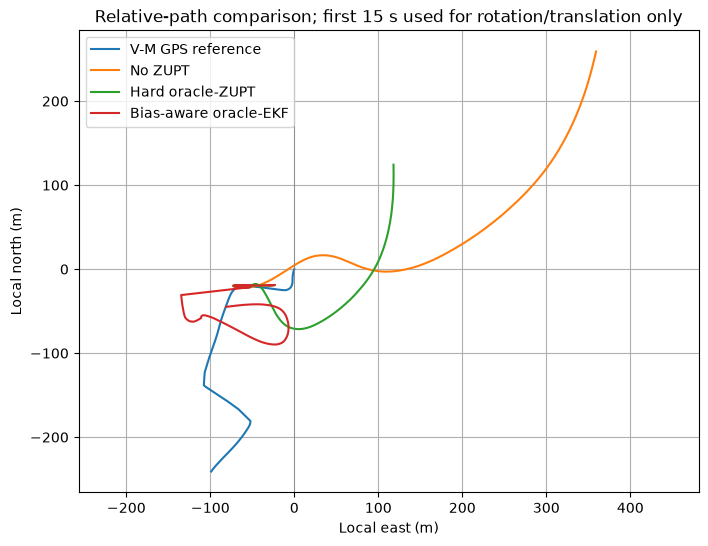

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# V-M GPS is only a reference for this offline comparison.
V_LAT = "Latitude (degrees)"
V_LON = "Longitude (degrees)"
V_GPS_SPEED = "Velocity (km/hr)"
V_SATELLITES = "No of GPS Satellites Available"

v_rows = BLOCKS[cal["block"]]["V"]

vm_t = np.asarray([dr_num(r, DR_V_TIME) for r in v_rows])
lat = np.asarray([dr_num(r, V_LAT) for r in v_rows])
lon = np.asarray([dr_num(r, V_LON) for r in v_rows])
gps_speed = np.asarray([dr_num(r, V_GPS_SPEED) for r in v_rows])
satellites = np.asarray([dr_num(r, V_SATELLITES) for r in v_rows])

good = np.isfinite(vm_t)
vm_t, lat, lon = vm_t[good], lat[good], lon[good]
gps_speed, satellites = gps_speed[good], satellites[good]

order = np.argsort(vm_t)
vm_t, lat, lon = vm_t[order], lat[order], lon[order]
gps_speed, satellites = gps_speed[order], satellites[order]
vm_t, unique = np.unique(vm_t, return_index=True)
lat, lon = lat[unique], lon[unique]
gps_speed, satellites = gps_speed[unique], satellites[unique]

# Match the latest V-M GPS row at or before each phone sample.
idx = np.searchsorted(vm_t, t, side="right") - 1
has_prior = idx >= 0
safe_idx = np.clip(idx, 0, len(vm_t) - 1)
age = t - vm_t[safe_idx]

gps_valid = (
    has_prior
    & (age >= 0) & (age <= 0.12)
    & np.isfinite(lat[safe_idx]) & np.isfinite(lon[safe_idx])
    & np.isfinite(gps_speed[safe_idx]) & (gps_speed[safe_idx] > 18.0)
    & np.isfinite(satellites[safe_idx]) & (satellites[safe_idx] > 0)
)

if gps_valid.sum() < 20:
    raise ValueError("Too few matched, moving GPS samples for a useful comparison.")

# Convert valid GPS positions to local east/north metres.
gps_lat = lat[safe_idx]
gps_lon = lon[safe_idx]
lat0 = np.deg2rad(gps_lat[gps_valid][0])
lon0 = np.deg2rad(gps_lon[gps_valid][0])
R_EARTH = 6_371_000.0

gps_xy = np.column_stack([
    R_EARTH * np.cos(lat0) * (np.deg2rad(gps_lon) - lon0),
    R_EARTH * (np.deg2rad(gps_lat) - lat0),
])

# Use the first 15 seconds only to estimate the arbitrary initial rotation
# and translation. Score the later GPS-valid samples.
relative_time = t - t[0]
fit = gps_valid & (relative_time <= 15.0)
score = gps_valid & (relative_time > 15.0)

if fit.sum() < 10 or score.sum() < 10:
    raise ValueError(
        f"Not enough GPS points for fit/score: fit={fit.sum()}, score={score.sum()}"
    )

def align_and_score(name, path):
    a = path[fit]
    b = gps_xy[fit]
    a_mean, b_mean = a.mean(axis=0), b.mean(axis=0)

    # Rotation only; deliberately do not fit scale.
    H = (a - a_mean).T @ (b - b_mean)
    U, _, Vt = np.linalg.svd(H)
    rotation = U @ Vt
    if np.linalg.det(rotation) < 0:
        Vt[-1, :] *= -1
        rotation = U @ Vt

    aligned = (path - a_mean) @ rotation + b_mean
    error = np.linalg.norm(aligned[score] - gps_xy[score], axis=1)

    print(
        f"{name}: fit points={fit.sum()}, scored points={score.sum()}, "
        f"median error={np.median(error):.1f} m, "
        f"RMSE={np.sqrt(np.mean(error**2)):.1f} m, "
        f"final scored error={error[-1]:.1f} m"
    )
    return aligned

aligned_no_zupt = align_and_score("No ZUPT", path_no_zupt)
aligned_hard_zupt = align_and_score("Hard oracle-ZUPT", path_oracle)
aligned_ekf = align_and_score("Bias-aware oracle-EKF", path_ekf)

plt.figure(figsize=(8, 6))
plt.plot(gps_xy[gps_valid, 0], gps_xy[gps_valid, 1], label="V-M GPS reference")
plt.plot(aligned_no_zupt[:, 0], aligned_no_zupt[:, 1], label="No ZUPT")
plt.plot(aligned_hard_zupt[:, 0], aligned_hard_zupt[:, 1], label="Hard oracle-ZUPT")
plt.plot(aligned_ekf[:, 0], aligned_ekf[:, 1], label="Bias-aware oracle-EKF")
plt.axvline(0, color="gray", linewidth=0.5)
plt.xlabel("Local east (m)")
plt.ylabel("Local north (m)")
plt.title("Relative-path comparison; first 15 s used for rotation/translation only")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()

In [12]:
import numpy as np

S_GPS_FIELDS = [
    "GPS LATITUDE (degrees)",
    "GPS LONGITUDE (degrees)",
    "GPS SPEED (Kmh)",
    "GPS ACCURACY (m)",
    "GPS ORIENTATION (°)",
    "GPS SATELLITES IN RANGE",
]

def gps_num(row, column):
    try:
        return float(row[column])
    except (KeyError, TypeError, ValueError):
        return np.nan

for block_name, block in BLOCKS.items():
    rows = block["S"]

    values = {
        col: np.asarray([gps_num(row, col) for row in rows])
        for col in S_GPS_FIELDS
    }

    print(f"\n{block_name}")
    for col, arr in values.items():
        finite = arr[np.isfinite(arr)]
        if len(finite):
            print(
                f"  {col}: numeric={len(finite)}/{len(arr)}, "
                f"min/median/p90/max="
                f"{np.min(finite):.3f}/"
                f"{np.median(finite):.3f}/"
                f"{np.percentile(finite, 90):.3f}/"
                f"{np.max(finite):.3f}"
            )
        else:
            print(f"  {col}: no numeric values")

    lat = values["GPS LATITUDE (degrees)"]
    lon = values["GPS LONGITUDE (degrees)"]
    speed = values["GPS SPEED (Kmh)"]
    sats = values["GPS SATELLITES IN RANGE"]
    heading = values["GPS ORIENTATION (°)"]

    print(
        "  independent counts:",
        f"finite lat/lon={np.sum(np.isfinite(lat) & np.isfinite(lon))},",
        f"speed >18 km/h={np.sum(np.isfinite(speed) & (speed > 18))},",
        f"satellites >0={np.sum(np.isfinite(sats) & (sats > 0))},",
        f"finite heading={np.sum(np.isfinite(heading))}"
    )

    print("  first 3 raw GPS rows:")
    for row in rows[:3]:
        print({col: row.get(col) for col in S_GPS_FIELDS})


prefix
  GPS LATITUDE (degrees): numeric=5642/5642, min/median/p90/max=52.402/52.403/52.422/52.424
  GPS LONGITUDE (degrees): numeric=5642/5642, min/median/p90/max=-1.523/-1.505/-1.501/-1.500
  GPS SPEED (Kmh): numeric=5642/5642, min/median/p90/max=0.000/8.140/17.310/18.620
  GPS ACCURACY (m): numeric=5642/5642, min/median/p90/max=2.000/3.000/4.000/8.000
  GPS ORIENTATION (°): numeric=5642/5642, min/median/p90/max=6.100/279.080/342.650/359.750
  GPS SATELLITES IN RANGE: no numeric values
  independent counts: finite lat/lon=5642, speed >18 km/h=270, satellites >0=0, finite heading=5642
  first 3 raw GPS rows:
{'GPS LATITUDE (degrees)': '52.402565', 'GPS LONGITUDE (degrees)': '-1.503471', 'GPS SPEED (Kmh)': '5.84', 'GPS ACCURACY (m)': '4', 'GPS ORIENTATION (°)': '92.89', 'GPS SATELLITES IN RANGE': '18 / 19'}
{'GPS LATITUDE (degrees)': '52.402565', 'GPS LONGITUDE (degrees)': '-1.503471', 'GPS SPEED (Kmh)': '5.84', 'GPS ACCURACY (m)': '4', 'GPS ORIENTATION (°)': '92.89', 'GPS SATELLITES 

In [13]:
import re
import numpy as np

def _phone_gps_float(row, column):
    try:
        return float(row.get(column, ""))
    except (TypeError, ValueError):
        return np.nan

def _satellites_used(value):
    # Example field: "18 / 19"; parse the leading count.
    match = re.match(r"^\s*(\d+)\s*/\s*\d+\s*$", str(value))
    return float(match.group(1)) if match else np.nan

for block_name, block in BLOCKS.items():
    s_rows, v_rows = block["S"], block["V"]

    # Phone GPS time is shifted onto the V-M timebase using the
    # previously validated offset.
    s_t = np.asarray([
        _phone_gps_float(r, S_TIME) / 1000 + PHONE_TO_VM_OFFSET_SECONDS
        for r in s_rows
    ])
    phone_speed = np.asarray([
        _phone_gps_float(r, "GPS SPEED (Kmh)") for r in s_rows
    ])
    accuracy = np.asarray([
        _phone_gps_float(r, "GPS ACCURACY (m)") for r in s_rows
    ])
    satellites = np.asarray([
        _satellites_used(r.get("GPS SATELLITES IN RANGE"))
        for r in s_rows
    ])
    lat = np.asarray([
        _phone_gps_float(r, "GPS LATITUDE (degrees)") for r in s_rows
    ])
    lon = np.asarray([
        _phone_gps_float(r, "GPS LONGITUDE (degrees)") for r in s_rows
    ])

    # Conservative position-quality screen; speed is deliberately not a gate.
    good = (
        np.isfinite(s_t) & np.isfinite(phone_speed)
        & np.isfinite(lat) & np.isfinite(lon)
        & np.isfinite(accuracy) & (accuracy <= 5)
        & np.isfinite(satellites) & (satellites >= 4)
    )

    s_t = s_t[good]
    phone_speed = phone_speed[good]
    accuracy = accuracy[good]
    satellites = satellites[good]
    lat, lon = lat[good], lon[good]

    # Keep only changes in the reported GPS state, rather than repeated
    # copies of one reading across adjacent phone-sensor rows.
    order = np.argsort(s_t)
    s_t, phone_speed = s_t[order], phone_speed[order]
    accuracy, satellites = accuracy[order], satellites[order]
    lat, lon = lat[order], lon[order]

    if len(s_t):
        signature = np.column_stack(
            [lat, lon, phone_speed, accuracy, satellites]
        )
        changed = np.r_[True, np.any(signature[1:] != signature[:-1], axis=1)]
        s_t, phone_speed = s_t[changed], phone_speed[changed]

    v_t = np.asarray([_phone_gps_float(r, V_TIME) for r in v_rows])
    ecu_speed = np.asarray([
        _phone_gps_float(r, V_ECU_SPEED) for r in v_rows
    ])
    v_good = np.isfinite(v_t) & np.isfinite(ecu_speed)
    v_t, ecu_speed = v_t[v_good], ecu_speed[v_good]

    if not len(s_t) or not len(v_t):
        print(f"{block_name}: no usable matched observations")
        continue

    v_order = np.argsort(v_t)
    v_t, ecu_speed = v_t[v_order], ecu_speed[v_order]
    v_t, unique_idx = np.unique(v_t, return_index=True)
    ecu_speed = ecu_speed[unique_idx]

    right = np.searchsorted(v_t, s_t)
    left_idx = np.clip(right - 1, 0, len(v_t) - 1)
    right_idx = np.clip(right, 0, len(v_t) - 1)
    nearest = np.where(
        np.abs(v_t[left_idx] - s_t) <= np.abs(v_t[right_idx] - s_t),
        left_idx, right_idx
    )

    age = np.abs(v_t[nearest] - s_t)
    matched = age <= 0.12
    if not np.any(matched):
        print(f"{block_name}: no matches within 0.12 s")
        continue

    delta = phone_speed[matched] - ecu_speed[nearest[matched]]
    p_speed = phone_speed[matched]
    e_speed = ecu_speed[nearest[matched]]
    corr = (
        np.corrcoef(p_speed, e_speed)[0, 1]
        if np.std(p_speed) > 0 and np.std(e_speed) > 0 else np.nan
    )

    print(
        f"{block_name}: GPS states={len(s_t)}, matched={matched.sum()}, "
        f"time-age p95={np.percentile(age[matched], 95):.3f}s"
    )
    print(
        f"  phone GPS vs ECU speed (km/h): "
        f"MAE={np.mean(np.abs(delta)):.2f}, "
        f"bias={np.mean(delta):+.2f}, correlation={corr:.3f}"
    )

prefix: GPS states=267, matched=232, time-age p95=0.001s
  phone GPS vs ECU speed (km/h): MAE=27.37, bias=-27.36, correlation=0.967
25% range: GPS states=268, matched=233, time-age p95=0.001s
  phone GPS vs ECU speed (km/h): MAE=31.53, bias=-30.75, correlation=0.740
50% range: GPS states=218, matched=218, time-age p95=0.050s
  phone GPS vs ECU speed (km/h): MAE=13.92, bias=-9.32, correlation=-0.200
75% range: GPS states=265, matched=265, time-age p95=0.050s
  phone GPS vs ECU speed (km/h): MAE=18.53, bias=-15.81, correlation=0.125


In [14]:
import re
import numpy as np

def _gnss_float(row, column):
    try:
        return float(row.get(column, ""))
    except (TypeError, ValueError):
        return np.nan

def _satellites_used(value):
    match = re.match(r"^\s*(\d+)\s*/\s*\d+\s*$", str(value))
    return float(match.group(1)) if match else np.nan

# Find the V-M GPS coordinate columns from the loaded headers.
v_headers = list(BLOCKS["prefix"]["V"][0].keys())

def _find_v_gps_column(term):
    hits = [c for c in v_headers if "GPS" in c.upper() and term in c.upper()]
    if len(hits) != 1:
        hits = [c for c in v_headers if term in c.upper()]
    if len(hits) != 1:
        raise ValueError(f"Could not uniquely identify V-M {term} column: {hits}")
    return hits[0]

V_GPS_LAT = _find_v_gps_column("LATITUDE")
V_GPS_LON = _find_v_gps_column("LONGITUDE")
print("V-M GPS columns:", V_GPS_LAT, "|", V_GPS_LON)

for block_name, block in BLOCKS.items():
    # Phone GPS observations, filtered by its reported accuracy and satellite count.
    s_rows = block["S"]
    s_t = np.asarray([
        _gnss_float(r, S_TIME) / 1000 + PHONE_TO_VM_OFFSET_SECONDS
        for r in s_rows
    ])
    s_lat = np.asarray([
        _gnss_float(r, "GPS LATITUDE (degrees)") for r in s_rows
    ])
    s_lon = np.asarray([
        _gnss_float(r, "GPS LONGITUDE (degrees)") for r in s_rows
    ])
    s_acc = np.asarray([
        _gnss_float(r, "GPS ACCURACY (m)") for r in s_rows
    ])
    s_sat = np.asarray([
        _satellites_used(r.get("GPS SATELLITES IN RANGE")) for r in s_rows
    ])

    s_ok = (
        np.isfinite(s_t) & np.isfinite(s_lat) & np.isfinite(s_lon)
        & np.isfinite(s_acc) & (s_acc <= 5)
        & np.isfinite(s_sat) & (s_sat >= 4)
        & ~((s_lat == 0) & (s_lon == 0))
    )
    s_t, s_lat, s_lon = s_t[s_ok], s_lat[s_ok], s_lon[s_ok]

    # Sort and collapse consecutive repeated phone GPS coordinates.
    order = np.argsort(s_t)
    s_t, s_lat, s_lon = s_t[order], s_lat[order], s_lon[order]
    if len(s_t):
        changed = np.r_[
            True, (s_lat[1:] != s_lat[:-1]) | (s_lon[1:] != s_lon[:-1])
        ]
        s_t, s_lat, s_lon = s_t[changed], s_lat[changed], s_lon[changed]

    # Valid V-M GPS coordinates and timestamps.
    v_rows = block["V"]
    v_t = np.asarray([_gnss_float(r, V_TIME) for r in v_rows])
    v_lat = np.asarray([_gnss_float(r, V_GPS_LAT) for r in v_rows])
    v_lon = np.asarray([_gnss_float(r, V_GPS_LON) for r in v_rows])

    v_ok = (
        np.isfinite(v_t) & np.isfinite(v_lat) & np.isfinite(v_lon)
        & (np.abs(v_lat) <= 90) & (np.abs(v_lon) <= 180)
        & ~((v_lat == 0) & (v_lon == 0))
    )
    v_t, v_lat, v_lon = v_t[v_ok], v_lat[v_ok], v_lon[v_ok]

    order = np.argsort(v_t)
    v_t, v_lat, v_lon = v_t[order], v_lat[order], v_lon[order]
    v_t, unique_idx = np.unique(v_t, return_index=True)
    v_lat, v_lon = v_lat[unique_idx], v_lon[unique_idx]

    if not len(s_t) or not len(v_t):
        print(f"{block_name}: no usable phone/V-M GPS points")
        continue

    # Match each phone point to the nearest V-M GPS timestamp.
    right = np.searchsorted(v_t, s_t)
    left_idx = np.clip(right - 1, 0, len(v_t) - 1)
    right_idx = np.clip(right, 0, len(v_t) - 1)
    nearest = np.where(
        np.abs(v_t[left_idx] - s_t) <= np.abs(v_t[right_idx] - s_t),
        left_idx, right_idx
    )
    age = np.abs(v_t[nearest] - s_t)
    matched = age <= 0.12

    if not np.any(matched):
        print(f"{block_name}: no GPS matches within 0.12 s")
        continue

    # Approximate local north/east separation between the two GPS positions.
    slat, slon = s_lat[matched], s_lon[matched]
    vlat, vlon = v_lat[nearest[matched]], v_lon[nearest[matched]]
    radius_m = 6_371_000
    north_m = radius_m * np.deg2rad(slat - vlat)
    east_m = (
        radius_m * np.cos(np.deg2rad((slat + vlat) / 2))
        * np.deg2rad(slon - vlon)
    )
    separation_m = np.hypot(north_m, east_m)

    print(
        f"{block_name}: matched={matched.sum()}/{len(s_t)}, "
        f"time-age p95={np.percentile(age[matched], 95):.3f}s; "
        f"phone-vs-V-M GPS separation "
        f"median={np.median(separation_m):.1f}m, "
        f"p90={np.percentile(separation_m, 90):.1f}m, "
        f"RMSE={np.sqrt(np.mean(separation_m**2)):.1f}m"
    )

V-M GPS columns: Latitude (degrees) | Longitude (degrees)
prefix: matched=52/59, time-age p95=0.001s; phone-vs-V-M GPS separation median=7.6m, p90=14.5m, RMSE=9.4m
25% range: matched=46/46, time-age p95=0.001s; phone-vs-V-M GPS separation median=9.6m, p90=14.7m, RMSE=16.9m
50% range: matched=52/52, time-age p95=0.050s; phone-vs-V-M GPS separation median=9861.5m, p90=11261.4m, RMSE=9828.4m
75% range: matched=63/63, time-age p95=0.050s; phone-vs-V-M GPS separation median=9150.5m, p90=10478.9m, RMSE=9397.4m
